# AgroVisionAI — PlantVillage (CNN) + Detecção de frutos (YOLO) + FastAPI

Notebook reorganizado para atender ao roteiro do Módulo 2. Execute as células **na ordem**.

## O que este notebook entrega
- EDA do PlantVillage: classes, contagem, balanceamento e imagens de exemplo.
- Divisão estratificada em treino/validação/teste (70%/15%/15%).
- Pipeline `tf.data`, Data Augmentation e CNN com `Conv2D`, `MaxPooling2D`, `Flatten` e `Dense`.
- Treinamento, salvamento `.keras`, métricas (acurácia, precisão, recall), matriz de confusão e análise de erros.
- Treinamento opcional de YOLOv8, YOLOv9 e YOLO11, se o dataset de frutos e `data.yaml` estiverem configurados.
- Geração de uma API FastAPI com `/classificar-folha` e `/detectar-fruto`.

**Importante:** PlantVillage é o dataset de folhas. Para treinar YOLO é necessário um dataset de frutos anotado com bounding boxes no formato YOLO. O notebook não inventa esse dataset: se `data.yaml` não existir, a etapa é ignorada com aviso.

## 0. Instalação e imports
Execute uma vez no ambiente do notebook. Em Colab, selecione GPU em *Ambiente de execução > Alterar tipo de ambiente de execução* para acelerar os treinos.

In [1]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn opencv-python-headless ultralytics fastapi uvicorn python-multipart

In [2]:
import os
import json
import random
import shutil
import subprocess
import sys
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

from tensorflow.keras import layers, models, regularizers
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU(s): []


## 1. Configuração e localização do PlantVillage
O caminho local informado é tentado primeiro. Se o notebook estiver no Colab/Kaggle e esse caminho não existir, o código tenta localizar o dataset em diretórios comuns. Se necessário, habilite o download pelo `kagglehub`.

In [3]:
from pathlib import Path

# Descobrir onde o Jupyter está executando
print("Diretório atual:", Path.cwd())

# Verificar pastas disponíveis
for pasta in Path.home().iterdir():
    print(pasta)

Diretório atual: /content
/root/.profile
/root/.bashrc
/root/.keras
/root/.local
/root/.cache
/root/.jupyter
/root/.gemini
/root/.tmux.conf
/root/.julia
/root/.wget-hsts
/root/.config
/root/.ipython
/root/.npm
/root/.launchpadlib
/root/.ssh


In [6]:
import os
import pandas as pd
from pathlib import Path
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to dataset files:", path)

# Utilizando o caminho baixado pelo KaggleHub
DATASET_DIR = Path(path)

# Verifica se existe uma subpasta PlantVillage
if (DATASET_DIR / "PlantVillage").exists():
    DATASET_DIR = DATASET_DIR / "PlantVillage"

print("Diretório utilizado:", DATASET_DIR)

# Procurando as imagens
caminhos_lista = []
classes_lista = []

for arquivo in DATASET_DIR.rglob("*"):
    if arquivo.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        caminhos_lista.append(str(arquivo))
        classes_lista.append(arquivo.parent.name)

# Criando DataFrame
df_plantvillage = pd.DataFrame({
    "caminho": caminhos_lista,
    "classe": classes_lista
})

print("Total de imagens:", len(df_plantvillage))
print("Total de classes:", df_plantvillage["classe"].nunique())

display(df_plantvillage.head())

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease
Diretório utilizado: /kaggle/input/plantdisease/PlantVillage
Total de imagens: 20638
Total de classes: 15


,caminho,classe
0,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
1,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
2,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
3,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
4,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot


In [7]:
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp"}

registros = []
for raiz, _, arquivos in os.walk(DATASET_DIR):
    for nome in arquivos:
        caminho = Path(raiz) / nome
        if caminho.suffix.lower() in EXTENSOES_IMAGEM:
            relativo = caminho.relative_to(DATASET_DIR)
            if len(relativo.parts) >= 2:
                classe = relativo.parts[0]
            else:
                continue
            registros.append({"caminho": str(caminho), "classe": classe})

df_imagens = pd.DataFrame(registros).drop_duplicates(subset="caminho").reset_index(drop=True)

if df_imagens.empty:
    raise ValueError(f"Nenhuma imagem foi encontrada em {DATASET_DIR}")

classes_unicas = sorted(df_imagens["classe"].unique())
NUM_CLASSES = len(classes_unicas)

print(f"Total de imagens: {len(df_imagens):,}")
print(f"Total de classes: {NUM_CLASSES}")
display(df_imagens.head())

Total de imagens: 20,638
Total de classes: 15


,caminho,classe
0,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
1,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
2,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
3,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot
4,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot


,classe,quantidade,percentual
0,Tomato__Tomato_YellowLeaf__Curl_Virus,3208,15.54
1,Tomato_Bacterial_spot,2127,10.31
2,Tomato_Late_blight,1909,9.25
3,Tomato_Septoria_leaf_spot,1771,8.58
4,Tomato_Spider_mites_Two_spotted_spider_mite,1676,8.12
5,Tomato_healthy,1591,7.71
6,Pepper__bell___healthy,1478,7.16
7,Tomato__Target_Spot,1404,6.80
8,Tomato_Early_blight,1000,4.85
9,Potato___Early_blight,1000,4.85


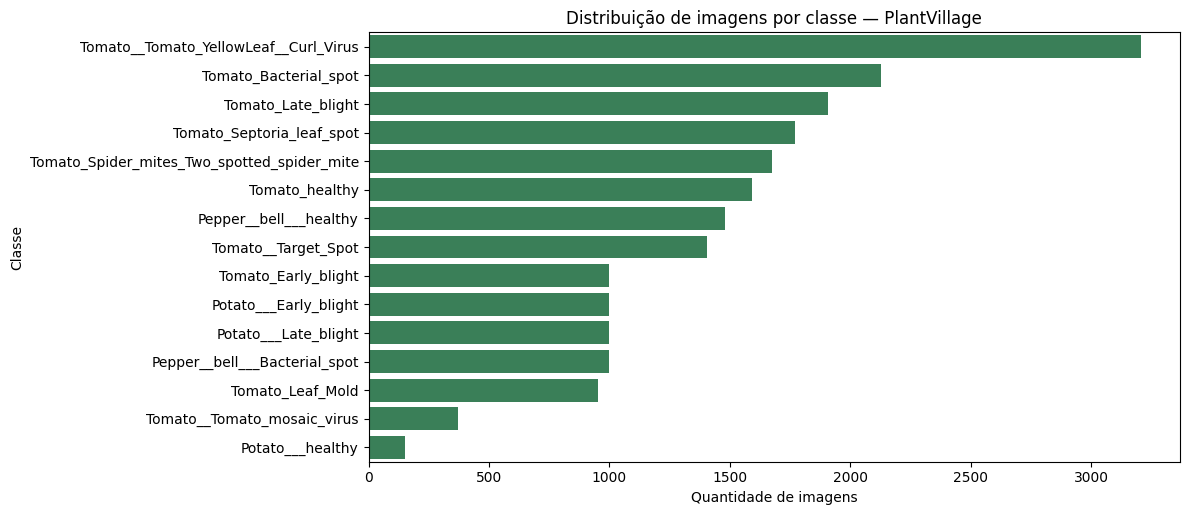

Menor classe: 152
Maior classe: 3208
Razão maior/menor: 21.11


In [8]:
contagem_classes = (
    df_imagens["classe"].value_counts()
    .rename_axis("classe")
    .reset_index(name="quantidade")
)
contagem_classes["percentual"] = (
    100 * contagem_classes["quantidade"] / len(df_imagens)
).round(2)

display(contagem_classes)

plt.figure(figsize=(12, max(5, 0.35 * len(contagem_classes))))
sns.barplot(data=contagem_classes, x="quantidade", y="classe", color="seagreen")
plt.title("Distribuição de imagens por classe — PlantVillage")
plt.xlabel("Quantidade de imagens")
plt.ylabel("Classe")
plt.tight_layout()
plt.show()

print("Menor classe:", contagem_classes["quantidade"].min())
print("Maior classe:", contagem_classes["quantidade"].max())
print("Razão maior/menor:", round(contagem_classes["quantidade"].max() / contagem_classes["quantidade"].min(), 2))

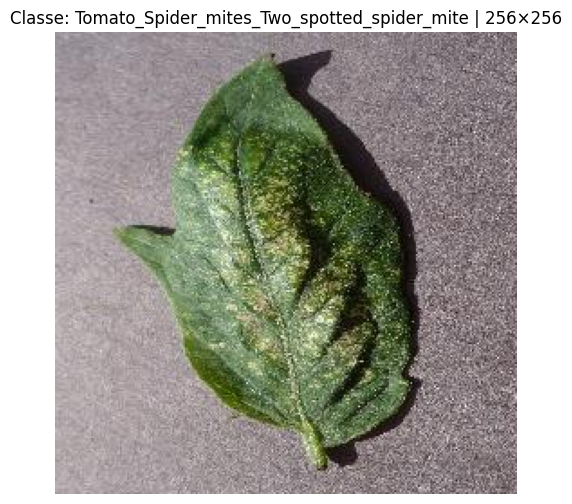

Caminho: /kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite/44755960-f542-4f8e-a1a0-94cf3cad8c21___Com.G_SpM_FL 1498.JPG
Shape BGR: (256, 256, 3)
Matriz NumPy (primeiros pixels):
 [[[156 149 156]
  [157 150 157]
  [163 156 163]]

 [[158 151 158]
  [156 149 156]
  [162 155 162]]

 [[152 145 152]
  [146 139 146]
  [150 143 150]]]


In [9]:
# Exibir uma imagem aleatória e suas dimensões
linha = df_imagens.sample(1, random_state=SEED).iloc[0]
imagem_bgr = cv2.imread(linha["caminho"])
if imagem_bgr is None:
    raise ValueError(f"OpenCV não conseguiu ler: {linha['caminho']}")

altura, largura = imagem_bgr.shape[:2]
imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(imagem_rgb)
plt.title(f"Classe: {linha['classe']} | {largura}×{altura}")
plt.axis("off")
plt.show()

print("Caminho:", linha["caminho"])
print("Shape BGR:", imagem_bgr.shape)
print("Matriz NumPy (primeiros pixels):\n", imagem_bgr[:3, :3, :])

## 3. Preparação dos conjuntos — treino, validação e teste
A divisão é estratificada para manter a proporção das classes em cada conjunto. A validação e o teste não recebem Data Augmentation.

In [10]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# 70% treino, 15% validação e 15% teste
df_treino, df_temp = train_test_split(
    df_imagens, test_size=0.30, random_state=SEED,
    stratify=df_imagens["classe"]
)
df_validacao, df_teste = train_test_split(
    df_temp, test_size=0.50, random_state=SEED,
    stratify=df_temp["classe"]
)

# IDs de classe consistentes e persistentes
classe_para_id = {nome: idx for idx, nome in enumerate(classes_unicas)}
id_para_classe = {idx: nome for nome, idx in classe_para_id.items()}

def preparar_arrays(df):
    caminhos = df["caminho"].astype(str).to_numpy()
    rotulos = df["classe"].map(classe_para_id).astype("int32").to_numpy()
    return caminhos, rotulos

X_treino, y_treino = preparar_arrays(df_treino)
X_val, y_val = preparar_arrays(df_validacao)
X_teste, y_teste = preparar_arrays(df_teste)

print(f"Treino: {len(X_treino):,} ({len(X_treino)/len(df_imagens):.1%})")
print(f"Validação: {len(X_val):,} ({len(X_val)/len(df_imagens):.1%})")
print(f"Teste: {len(X_teste):,} ({len(X_teste)/len(df_imagens):.1%})")

Treino: 14,446 (70.0%)
Validação: 3,096 (15.0%)
Teste: 3,096 (15.0%)


In [11]:
def carregar_imagem(caminho, rotulo):
    conteudo = tf.io.read_file(caminho)
    imagem = tf.io.decode_image(conteudo, channels=3, expand_animations=False)
    imagem.set_shape([None, None, 3])
    imagem = tf.image.resize(imagem, IMG_SIZE)
    # Mantém pixels em [0,255]; Rescaling ficará dentro do modelo.
    imagem = tf.cast(imagem, tf.float32)
    return imagem, rotulo

def criar_dataset(caminhos, rotulos, treino=False):
    ds = tf.data.Dataset.from_tensor_slices((caminhos, rotulos))
    if treino:
        ds = ds.shuffle(buffer_size=min(len(caminhos), 5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(carregar_imagem, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    # Evita cache em RAM de todo o PlantVillage; prefetch mantém o pipeline eficiente.
    return ds.prefetch(AUTOTUNE)

train_ds = criar_dataset(X_treino, y_treino, treino=True)
val_ds = criar_dataset(X_val, y_val)
test_ds = criar_dataset(X_teste, y_teste)

for lote_imagens, lote_rotulos in train_ds.take(1):
    print("Shape do lote:", lote_imagens.shape)
    print("Shape dos rótulos:", lote_rotulos.shape)
    print("Faixa de pixels:", float(tf.reduce_min(lote_imagens)), "a", float(tf.reduce_max(lote_imagens)))

Shape do lote: (32, 128, 128, 3)
Shape dos rótulos: (32,)
Faixa de pixels: 0.0 a 255.0


## 4. Data Augmentation e arquitetura CNN
A arquitetura aplica convolução para extrair características, pooling para reduzir a dimensão espacial, `Flatten` para transformar mapas de características em vetor e camadas densas para classificar. O `Rescaling` normaliza pixels dentro do modelo.

In [12]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.10),
], name="data_augmentation")

model_cnn = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.Rescaling(1.0 / 255.0),
    data_augmentation,

    # Bloco convolucional 1: aprende bordas e texturas simples
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Bloco convolucional 2: aprende padrões mais complexos
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Bloco convolucional 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Vetorização e classificação
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="CNN_PlantVillage")

model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()

Model: "CNN_PlantVillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,383 (16.37 MB)

 Trainable params: 4,289,999 (16.37 MB)

 Non-trainable params: 384 (1.50 KB)

In [14]:
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_CNN_PATH = ARTIFACTS_DIR / "modelo_folhas.keras"
CLASS_NAMES_PATH = ARTIFACTS_DIR / "classes_folhas.json"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_CNN_PATH),
        monitor="val_loss", save_best_only=True
    )
]

EPOCHS = 10  # Ajuste conforme o tempo/GPU disponível.

history = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Salvar o modelo final e o mapeamento de classes
model_cnn.save(MODEL_CNN_PATH)
with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(classes_unicas, f, ensure_ascii=False, indent=2)

print("Modelo salvo em:", MODEL_CNN_PATH.resolve())
print("Classes salvas em:", CLASS_NAMES_PATH.resolve())

Epoch 1/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 764s 2s/step - accuracy: 0.2898 - loss: 2.2373 - val_accuracy: 0.3850 - val_loss: 1.8399 - learning_rate: 0.0010
Epoch 2/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 805s 2s/step - accuracy: 0.3242 - loss: 2.1026 - val_accuracy: 0.3217 - val_loss: 4.2952 - learning_rate: 0.0010
Epoch 3/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 808s 2s/step - accuracy: 0.3768 - loss: 1.9486 - val_accuracy: 0.3676 - val_loss: 1.9184 - learning_rate: 0.0010
Epoch 4/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 791s 2s/step - accuracy: 0.4334 - loss: 1.7730 - val_accuracy: 0.4209 - val_loss: 3.0480 - learning_rate: 5.0000e-04
Epoch 5/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 800s 2s/step - accuracy: 0.4619 - loss: 1.6837 - val_accuracy: 0.5759 - val_loss: 1.3744 - learning_rate: 5.0000e-04
Epoch 6/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 807s 2s/step - accuracy: 0.4795 - loss: 1.6297 - val_accuracy: 0.3915 - val_loss: 3.3660 - learning_rate: 5.0000e-04
Epoch 7/10
452/452 ━━━━━━━━━━━━━━━━━━━━ 764s 2s/step - accuracy: 0.500

## 5. Avaliação: acurácia, precisão, recall e análise de erros
As métricas finais são calculadas no conjunto de teste, que não participou do ajuste dos pesos.

In [15]:
# Previsões do conjunto de teste
y_true = np.concatenate([y.numpy() for _, y in test_ds])
probabilidades = model_cnn.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilidades, axis=1)

acuracia = accuracy_score(y_true, y_pred)
precisao_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)

print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão macro: {precisao_macro:.4f}")
print(f"Recall macro:   {recall_macro:.4f}")
print("\nRelatório por classe:")
print(classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=classes_unicas, zero_division=0
))

97/97 ━━━━━━━━━━━━━━━━━━━━ 35s 360ms/step
Acurácia:  0.7016
Precisão macro: 0.6590
Recall macro:   0.6078

Relatório por classe:
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.59      0.13      0.21       149
                     Pepper__bell___healthy       0.54      0.91      0.68       221
                      Potato___Early_blight       0.76      0.92      0.83       150
                       Potato___Late_blight       0.82      0.53      0.64       150
                           Potato___healthy       0.00      0.00      0.00        23
                      Tomato_Bacterial_spot       0.93      0.83      0.88       319
                        Tomato_Early_blight       0.63      0.35      0.45       150
                         Tomato_Late_blight       0.81      0.55      0.66       287
                           Tomato_Leaf_Mold       0.82      0.57      0.67       143
                  To

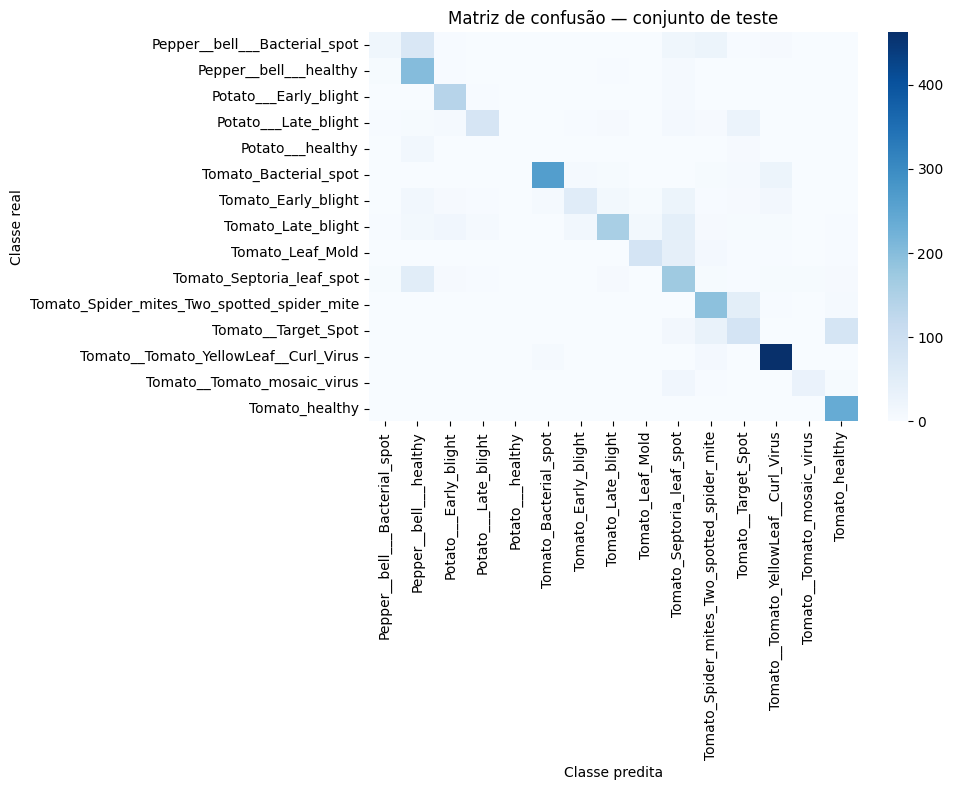

Erros: 924 de 3096 imagens


,caminho,classe,classe_real,classe_predita,confianca
0,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato__Target_Spot,Tomato__Target_Spot,Tomato_healthy,0.434749
4,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato__Target_Spot,Tomato__Target_Spot,Tomato_Spider_mites_Two_spotted_spider_mite,0.608432
5,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,Pepper__bell___healthy,0.197134
14,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Early_blight,Tomato_Early_blight,Tomato__Target_Spot,0.179266
17,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,Pepper__bell___healthy,0.179369
22,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,Pepper__bell___healthy,0.197134
23,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___healthy,Pepper__bell___healthy,Pepper__bell___Bacterial_spot,0.146720
24,/kaggle/input/plantdisease/PlantVillage/Potato...,Potato___Late_blight,Potato___Late_blight,Tomato_Septoria_leaf_spot,0.237485
28,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Leaf_Mold,Tomato_Leaf_Mold,Tomato_Spider_mites_Two_spotted_spider_mite,0.623274
31,/kaggle/input/plantdisease/PlantVillage/Tomato...,Tomato_Bacterial_spot,Tomato_Bacterial_spot,Tomato__Tomato_YellowLeaf__Curl_Virus,0.813255


In [17]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(max(10, NUM_CLASSES * 0.55), max(8, NUM_CLASSES * 0.45)))
sns.heatmap(
    cm, cmap="Blues", annot=(NUM_CLASSES <= 12), fmt="d",
    xticklabels=classes_unicas, yticklabels=classes_unicas
)
plt.title("Matriz de confusão — conjunto de teste")
plt.xlabel("Classe predita")
plt.ylabel("Classe real")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# DataFrame de erros para inspeção manual
df_resultados = df_teste.reset_index(drop=True).copy()
df_resultados["classe_real"] = [id_para_classe[int(i)] for i in y_true]
df_resultados["classe_predita"] = [id_para_classe[int(i)] for i in y_pred]
df_resultados["confianca"] = probabilidades.max(axis=1)
df_erros = df_resultados[df_resultados["classe_real"] != df_resultados["classe_predita"]]

print(f"Erros: {len(df_erros)} de {len(df_resultados)} imagens")
display(df_erros.head(20))

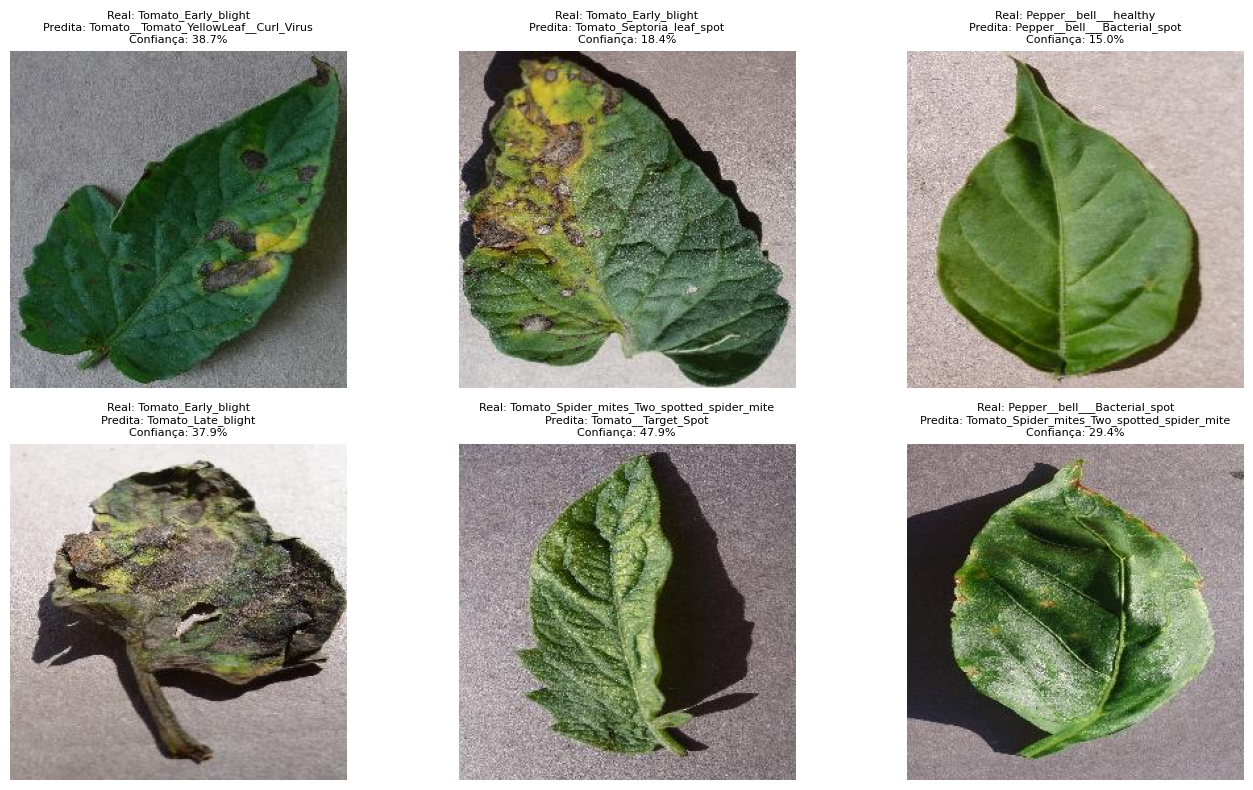

In [18]:
# Visualizar até 6 erros de classificação
if not df_erros.empty:
    amostra_erros = df_erros.sample(min(6, len(df_erros)), random_state=SEED)
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, linha) in zip(axes.flat, amostra_erros.iterrows()):
        img = cv2.imread(linha["caminho"])
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)
            ax.set_title(
                f"Real: {linha['classe_real']}\nPredita: {linha['classe_predita']}\n"
                f"Confiança: {linha['confianca']:.1%}",
                fontsize=8
            )
            ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum erro encontrado no conjunto de teste.")

## 6. Reflexão sobre limitações do PlantVillage

O PlantVillage é útil para desenvolver e comparar modelos, mas suas imagens foram obtidas em condições relativamente controladas. Em lavouras reais, o desempenho pode cair devido a:
- variações de iluminação, sombras, reflexos e clima;
- fundos complexos, folhas sobrepostas e diferentes ângulos;
- diferenças de câmera, resolução e distância;
- sintomas em estágios diferentes ou doenças simultâneas;
- distribuição de classes diferente da distribuição real.

Data Augmentation ajuda a simular algumas variações, mas não substitui a validação com imagens reais coletadas em campo. O modelo deve ser apresentado como apoio à triagem, não como diagnóstico agronômico definitivo.

## 7. YOLO — treinamento de frutos (v8, v9 e v11)

**Pré-requisito:** dataset de frutos anotado em formato YOLO e arquivo `data.yaml` válido. O `data.yaml` deve apontar para as imagens e rótulos de treino/validação/teste e definir `names`.

Ajuste `FRUIT_DATA_YAML` para o caminho real do seu arquivo. Por padrão, o treinamento fica desativado para não iniciar três treinos pesados sem confirmação do caminho/dataset.

In [19]:
FRUIT_DATA_YAML = "/content/AgroVisionAI_Project/AgroVisionAI/datasets/apple_tomato/data.yaml"
TREINAR_YOLO = False  # Mude para True somente depois de confirmar o data.yaml.
YOLO_EPOCHS = 50
YOLO_IMGSZ = 640
YOLO_BATCH = 16

from ultralytics import YOLO

YOLO_CONFIGS = {
    "v8": "yolov8n.pt",
    "v9": "yolov9c.pt",
    "v11": "yolo11n.pt",  # Nome oficial dos pesos YOLO11 na Ultralytics
}

YOLO_MODELS_DIR = ARTIFACTS_DIR / "yolo"
YOLO_MODELS_DIR.mkdir(parents=True, exist_ok=True)

def treinar_yolo(versao, pesos_base, data_yaml):
    modelo = YOLO(pesos_base)
    resultado = modelo.train(
        data=str(data_yaml),
        epochs=YOLO_EPOCHS,
        imgsz=YOLO_IMGSZ,
        batch=YOLO_BATCH,
        project=str(ARTIFACTS_DIR / "runs"),
        name=f"treino_{versao}",
        patience=10,
        plots=True,
        verbose=True
    )
    best_pt = Path(resultado.save_dir) / "weights" / "best.pt"
    if not best_pt.exists():
        raise FileNotFoundError(f"best.pt não foi gerado em {best_pt}")
    destino = YOLO_MODELS_DIR / f"yolo_{versao}_best.pt"
    shutil.copy2(best_pt, destino)
    print(f"Melhores pesos {versao} copiados para: {destino}")
    return modelo, resultado

if TREINAR_YOLO:
    yaml_path = Path(FRUIT_DATA_YAML)
    if not yaml_path.is_file():
        raise FileNotFoundError(
            f"data.yaml não encontrado: {yaml_path}. Corrija FRUIT_DATA_YAML antes do treino."
        )
    yolo_treinos = {}
    for versao, pesos in YOLO_CONFIGS.items():
        yolo_treinos[versao] = treinar_yolo(versao, pesos, yaml_path)
else:
    print("Treino YOLO não iniciado. Configure FRUIT_DATA_YAML e TREINAR_YOLO=True.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Treino YOLO não iniciado. Configure FRUIT_DATA_YAML e TREINAR_YOLO=True.


### Avaliação YOLO

Após treinar, a Ultralytics gera métricas no diretório `artifacts/runs/treino_<versao>`, incluindo Precision, Recall, mAP50 e mAP50-95, além de gráficos de treino/validação e matrizes de confusão. Compare as versões usando o mesmo dataset, divisão, `imgsz` e condições de treinamento.

Bounding boxes devem ser avaliadas por IoU e mAP. Falso positivo é uma caixa em região sem fruto ou com classe incorreta; falso negativo é um fruto anotado que o modelo não detectou. Inspecione também imagens com caixas desenhadas, não apenas os valores agregados.

In [20]:
# Validação dos pesos treinados, quando existirem
resultados_validacao_yolo = {}
for versao in YOLO_CONFIGS:
    pesos = YOLO_MODELS_DIR / f"yolo_{versao}_best.pt"
    if pesos.exists() and Path(FRUIT_DATA_YAML).is_file():
        modelo = YOLO(str(pesos))
        resultados_validacao_yolo[versao] = modelo.val(
            data=FRUIT_DATA_YAML, imgsz=YOLO_IMGSZ
        )
        print(f"Validação concluída: {versao}")
    else:
        print(f"Pulando {versao}: pesos ou data.yaml ainda não disponíveis.")

Pulando v8: pesos ou data.yaml ainda não disponíveis.
Pulando v9: pesos ou data.yaml ainda não disponíveis.
Pulando v11: pesos ou data.yaml ainda não disponíveis.


## 8. Gerar a API FastAPI

A API usa o modelo CNN salvo e carrega uma vez os pesos YOLO disponíveis na inicialização. O endpoint de folhas devolve a classe detalhada, condição (saudável/doente) e confiança. O endpoint de frutos devolve caixas, classes e confiança.

Os arquivos `artifacts/modelo_folhas.keras`, `artifacts/classes_folhas.json` e `artifacts/yolo/yolo_<versao>_best.pt` precisam estar no mesmo ambiente em que a API será iniciada.

In [21]:
api_code = r'''
from pathlib import Path
import json
import os
import tempfile

import cv2
import numpy as np
import tensorflow as tf
from fastapi import FastAPI, UploadFile, File, HTTPException, Query
from ultralytics import YOLO

BASE_DIR = Path(__file__).resolve().parent
ARTIFACTS_DIR = BASE_DIR / "artifacts"
CNN_PATH = ARTIFACTS_DIR / "modelo_folhas.keras"
CLASSES_PATH = ARTIFACTS_DIR / "classes_folhas.json"
YOLO_DIR = ARTIFACTS_DIR / "yolo"

app = FastAPI(title="AgroVisionAI API", version="1.0.0")

if not CNN_PATH.is_file() or not CLASSES_PATH.is_file():
    raise RuntimeError(
        "Modelo CNN ou arquivo de classes ausente. Execute o treinamento da CNN antes de iniciar a API."
    )

cnn_model = tf.keras.models.load_model(CNN_PATH)
with open(CLASSES_PATH, "r", encoding="utf-8") as f:
    class_names = json.load(f)

# Carrega apenas os modelos YOLO que existem, uma única vez.
yolo_models = {}
for version in ("v8", "v9", "v11"):
    weights = YOLO_DIR / f"yolo_{version}_best.pt"
    if weights.is_file():
        yolo_models[version] = YOLO(str(weights))

async def upload_to_bgr(file: UploadFile):
    content = await file.read()
    if not content:
        raise HTTPException(status_code=400, detail="Arquivo vazio.")
    array = np.frombuffer(content, dtype=np.uint8)
    image = cv2.imdecode(array, cv2.IMREAD_COLOR)
    if image is None:
        raise HTTPException(status_code=400, detail="Não foi possível decodificar a imagem.")
    return image

@app.get("/health")
def health():
    return {
        "status": "ok",
        "cnn_loaded": True,
        "yolo_models_loaded": sorted(yolo_models.keys())
    }

@app.post("/classificar-folha")
async def classificar_folha(file: UploadFile = File(...)):
    image_bgr = await upload_to_bgr(file)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_rgb = cv2.resize(image_rgb, (128, 128), interpolation=cv2.INTER_AREA)
    batch = np.expand_dims(image_rgb.astype(np.float32), axis=0)

    probabilities = cnn_model.predict(batch, verbose=0)[0]
    class_id = int(np.argmax(probabilities))
    predicted_class = class_names[class_id]
    condition = "saudavel" if "healthy" in predicted_class.lower() else "doente"

    return {
        "classe": predicted_class,
        "condicao": condition,
        "confianca": float(probabilities[class_id])
    }

@app.post("/detectar-fruto")
async def detectar_fruto(
    file: UploadFile = File(...),
    modelo: str = Query("v8", pattern="^(v8|v9|v11)$")
):
    if modelo not in yolo_models:
        raise HTTPException(
            status_code=503,
            detail=f"Pesos YOLO {modelo} não carregados. Treine o modelo e coloque yolo_{modelo}_best.pt em artifacts/yolo/."
        )

    image_bgr = await upload_to_bgr(file)
    results = yolo_models[modelo].predict(source=image_bgr, verbose=False)
    result = results[0]

    detections = []
    if result.boxes is not None:
        for box in result.boxes:
            class_id = int(box.cls.item())
            detections.append({
                "classe_id": class_id,
                "classe": yolo_models[modelo].names[class_id],
                "confianca": float(box.conf.item()),
                "bbox_xyxy": [float(v) for v in box.xyxy[0].tolist()]
            })

    return {
        "modelo": modelo,
        "quantidade_deteccoes": len(detections),
        "deteccoes": detections
    }
'''

api_path = Path("api.py")
api_path.write_text(api_code, encoding="utf-8")
print("API criada em:", api_path.resolve())

API criada em: /content/api.py


## 9. Executar e testar a API

No terminal, na pasta que contém `api.py` e `artifacts/`, execute:

```bash
uvicorn api:app --host 0.0.0.0 --port 8000 --reload
```

Abra `http://127.0.0.1:8000/docs` para testar pelo Swagger.

### Postman
- Método: `POST`
- URL folhas: `http://127.0.0.1:8000/classificar-folha`
- URL frutos: `http://127.0.0.1:8000/detectar-fruto?modelo=v8` (ou `v9`, `v11`)
- Aba **Body** → **form-data**
- Chave: `file`, tipo **File**, selecione uma imagem.
- Envie a requisição.

O endpoint de frutos retorna `503` se os pesos da versão solicitada ainda não tiverem sido treinados/salvos.